# V1 — previsões de crescimento de dengue em 4, 8, 12 e 16 semanas

Três modelos: Random Forest, RNN e LSTM. Entradas sem ENSO, escolhidas pelos
resultados das rodadas anteriores. Cada modelo é a média de cinco sementes fixas.

**Alvo:** casos na semana `t+h` pelo menos 50% acima da média das quatro semanas
anteriores à emissão (`t−4` a `t−1`). É crescimento de casos, não confirmação de surto.

A data de referência é automaticamente a última semana da base. O código funciona
com uma base atualizada sem alterar artificialmente as datas. O acerto histórico
é calculado por modelo e horizonte; não é uma probabilidade individual de acerto.


## 1. Bibliotecas e configuração

O código analítico completo está em `v1/estudo.py`, com funções de importação,
tratamento, arquiteturas, treinamento, avaliação, explicabilidade e exportação.
Não importa nem executa os notebooks antigos.


In [1]:
%matplotlib inline
from pathlib import Path
import runpy
from IPython.display import display, Image

current = Path.cwd().resolve()
PROJECT_ROOT = current.parent if current.name == 'v1' else current
api = runpy.run_path(str(PROJECT_ROOT / 'v1/estudo.py'))
display(api['CONFIG'])


/home/lorenzo/.local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'version': 'v1.0.0',
 'seeds': [42, 123, 2025, 7, 99],
 'horizons_weeks': [4, 8, 12, 16],
 'sequence_length': 12,
 'growth_fraction': 0.5,
 'baseline_weeks': 4,
 'decision_threshold': 0.5,
 'features': ['casos_dengue',
  'temperatura_media',
  'umidade_media',
  'chuva_total',
  'semana_sin',
  'semana_cos'],
 'availability_lag_weeks': 1,
 'train_end': '2019-12-22',
 'validation_end': '2022-12-25',
 'forest_tree_counts': [25, 50, 100, 200],
 'forest_max_depth': 6,
 'forest_min_samples_leaf': 2,
 'network_hidden_size': 24,
 'learning_rate': 0.003,
 'max_epochs': 150,
 'patience': 20,
 'network_selection': 'menor perda BCE de validação',
 'forest_selection': 'maior F1 de validação',
 'ensemble': 'média das saídas das cinco sementes predefinidas; nenhuma semente é escolhida',
 'pr_auc_definition': 'sklearn.average_precision_score',
 'target': 'casos(t+h) >= 1,5 × média de casos(t−4 ... t−1)',
 'historical_evaluation': 'retrospectiva e exploratória; período já examinado no desenvolvimento

## 2. Dataset para DataFrame pandas

Casos, temperatura, umidade, chuva e sazonalidade semanal. Nenhuma entrada ENSO.
A auditoria exige continuidade semanal e atributos completos. As unidades são:
casos/semana, °C, umidade %, chuva mm/semana e sazonalidade adimensional.


In [2]:
df, features, audit = api['load_data'](PROJECT_ROOT)
display(df[['dt_pri_sem', 'n dengue']].head())
display(features.head())
display(audit)


,dt_pri_sem,n dengue
0,2010-12-26,235
1,2011-01-02,357
2,2011-01-09,468
3,2011-01-16,782
4,2011-01-23,833


,casos_dengue,temperatura_media,umidade_media,chuva_total,semana_sin,semana_cos
0,235.0,26.21,79.71,37.8,6.432491e-16,1.000000
1,357.0,24.85,90.28,80.3,1.205367e-01,0.992709
2,468.0,25.56,88.05,85.0,2.393157e-01,0.970942
3,782.0,26.68,82.34,16.3,3.546049e-01,0.935016
4,833.0,28.65,70.24,6.7,4.647232e-01,0.885456


{'n_weeks': 784,
 'first_week': '2010-12-26',
 'last_week': '2025-12-28',
 'source_sha256': '8f7e34aea861bc12538dd839057211d579398a5723bbe371ad127c386b59a779'}

## 3. Tratamento e protocolo

- Janelas reais de 12 semanas, disponíveis com atraso de uma semana.
- Mesmo conteúdo para RF (janela achatada) e redes (sequência).
- Treino por data-alvo até 22/12/2019; validação com emissão posterior e alvo até
  25/12/2022; teste com emissão posterior. Amostras que cruzariam fronteiras são removidas.
- Scaler ajustado só no treino; alvos e splits recalculados para cada horizonte.
- RF: maior F1 na validação; redes: menor perda BCE, paciência 20, até 150 épocas.
- Sementes 42/123/2025/7/99; nenhuma é escolhida. Limiar fixo 0,5.
- A avaliação histórica ocorre depois de congelar todos os modelos. Esse período
  já foi examinado antes: a avaliação é retrospectiva e exploratória.
- Não há ajuste ao teste nem refit posterior: a projeção usa os mesmos modelos avaliados.


## 4. Execução completa dos três modelos e quatro horizontes

A execução gera EDA, gráficos de F1/precisão/recall/ROC-AUC/PR-AUC/acurácia,
curvas ROC, matrizes de confusão e históricos. SHAP e Gini explicam RF;
Saliency e Integrated Gradients explicam as redes. A saída explicada é a média
das cinco saídas, na escala 0–1; zero padronizado é a média do treino.

Cada combinação exporta métricas, explicabilidade global e da projeção, conclusão,
previsão e resultado completo em JSON. Também salva CSV, PNG/SVG, scalers e modelos.


In [3]:
summary = api['run_study'](PROJECT_ROOT)
display(summary.query("split == 'teste'").round(4))


Treinando Random Forest — 4 semanas


Concluído Random Forest — 4 semanas acurácia histórica: 0.8758


Treinando RNN — 4 semanas


Concluído RNN — 4 semanas acurácia histórica: 0.9085


Treinando LSTM — 4 semanas


Concluído LSTM — 4 semanas acurácia histórica: 0.8758


... (15 outputs left out)

Concluído RNN — 16 semanas acurácia histórica: 0.8936


Treinando LSTM — 16 semanas


Concluído LSTM — 16 semanas acurácia histórica: 0.8723


,horizon_weeks,model,split,f1,precision,recall,roc_auc,pr_auc,accuracy,n_samples,n_positive,predicted_positive
2,4,random_forest,teste,0.7397,1.0000,0.5870,0.9303,0.8883,0.8758,153,46,27
5,4,rnn,teste,0.8250,0.9706,0.7174,0.9315,0.9158,0.9085,153,46,34
8,4,lstm,teste,0.7397,1.0000,0.5870,0.9466,0.9300,0.8758,153,46,27
11,8,random_forest,teste,0.0364,1.0000,0.0185,0.8585,0.7209,0.6443,149,54,1
14,8,rnn,teste,0.7312,0.8718,0.6296,0.9257,0.8912,0.8322,149,54,39
17,8,lstm,teste,0.6207,0.8182,0.5000,0.9045,0.8342,0.7785,149,54,33
20,12,random_forest,teste,0.3478,0.9231,0.2143,0.9228,0.8585,0.6897,145,56,13
23,12,rnn,teste,0.7810,0.8367,0.7321,0.9282,0.8781,0.8414,145,56,49
26,12,lstm,teste,0.7723,0.8667,0.6964,0.9416,0.9071,0.8414,145,56,45
29,16,random_forest,teste,0.1875,0.6667,0.1091,0.9474,0.8203,0.6312,141,55,9


## 5. Resultados e saídas para consumo

`results/catalogo.json` indica os arquivos por modelo e horizonte.
Em `results/horizontes/04_semanas/random_forest`, por exemplo:
`previsao.json`, `metricas.json`, `explicabilidade.json`, `conclusao.json` e
`resultado_completo.json`. O mesmo padrão vale para todos os horizontes e modelos.

A conclusão contém a data-alvo, sim/não, critério, acerto histórico e número de
semanas avaliadas, além de aviso experimental. O escore não calibrado é separado
explicitamente da taxa histórica de acerto. Não há aviso sobre idade da base nos
JSONs de previsão. Limitações científicas ficam no relatório técnico.


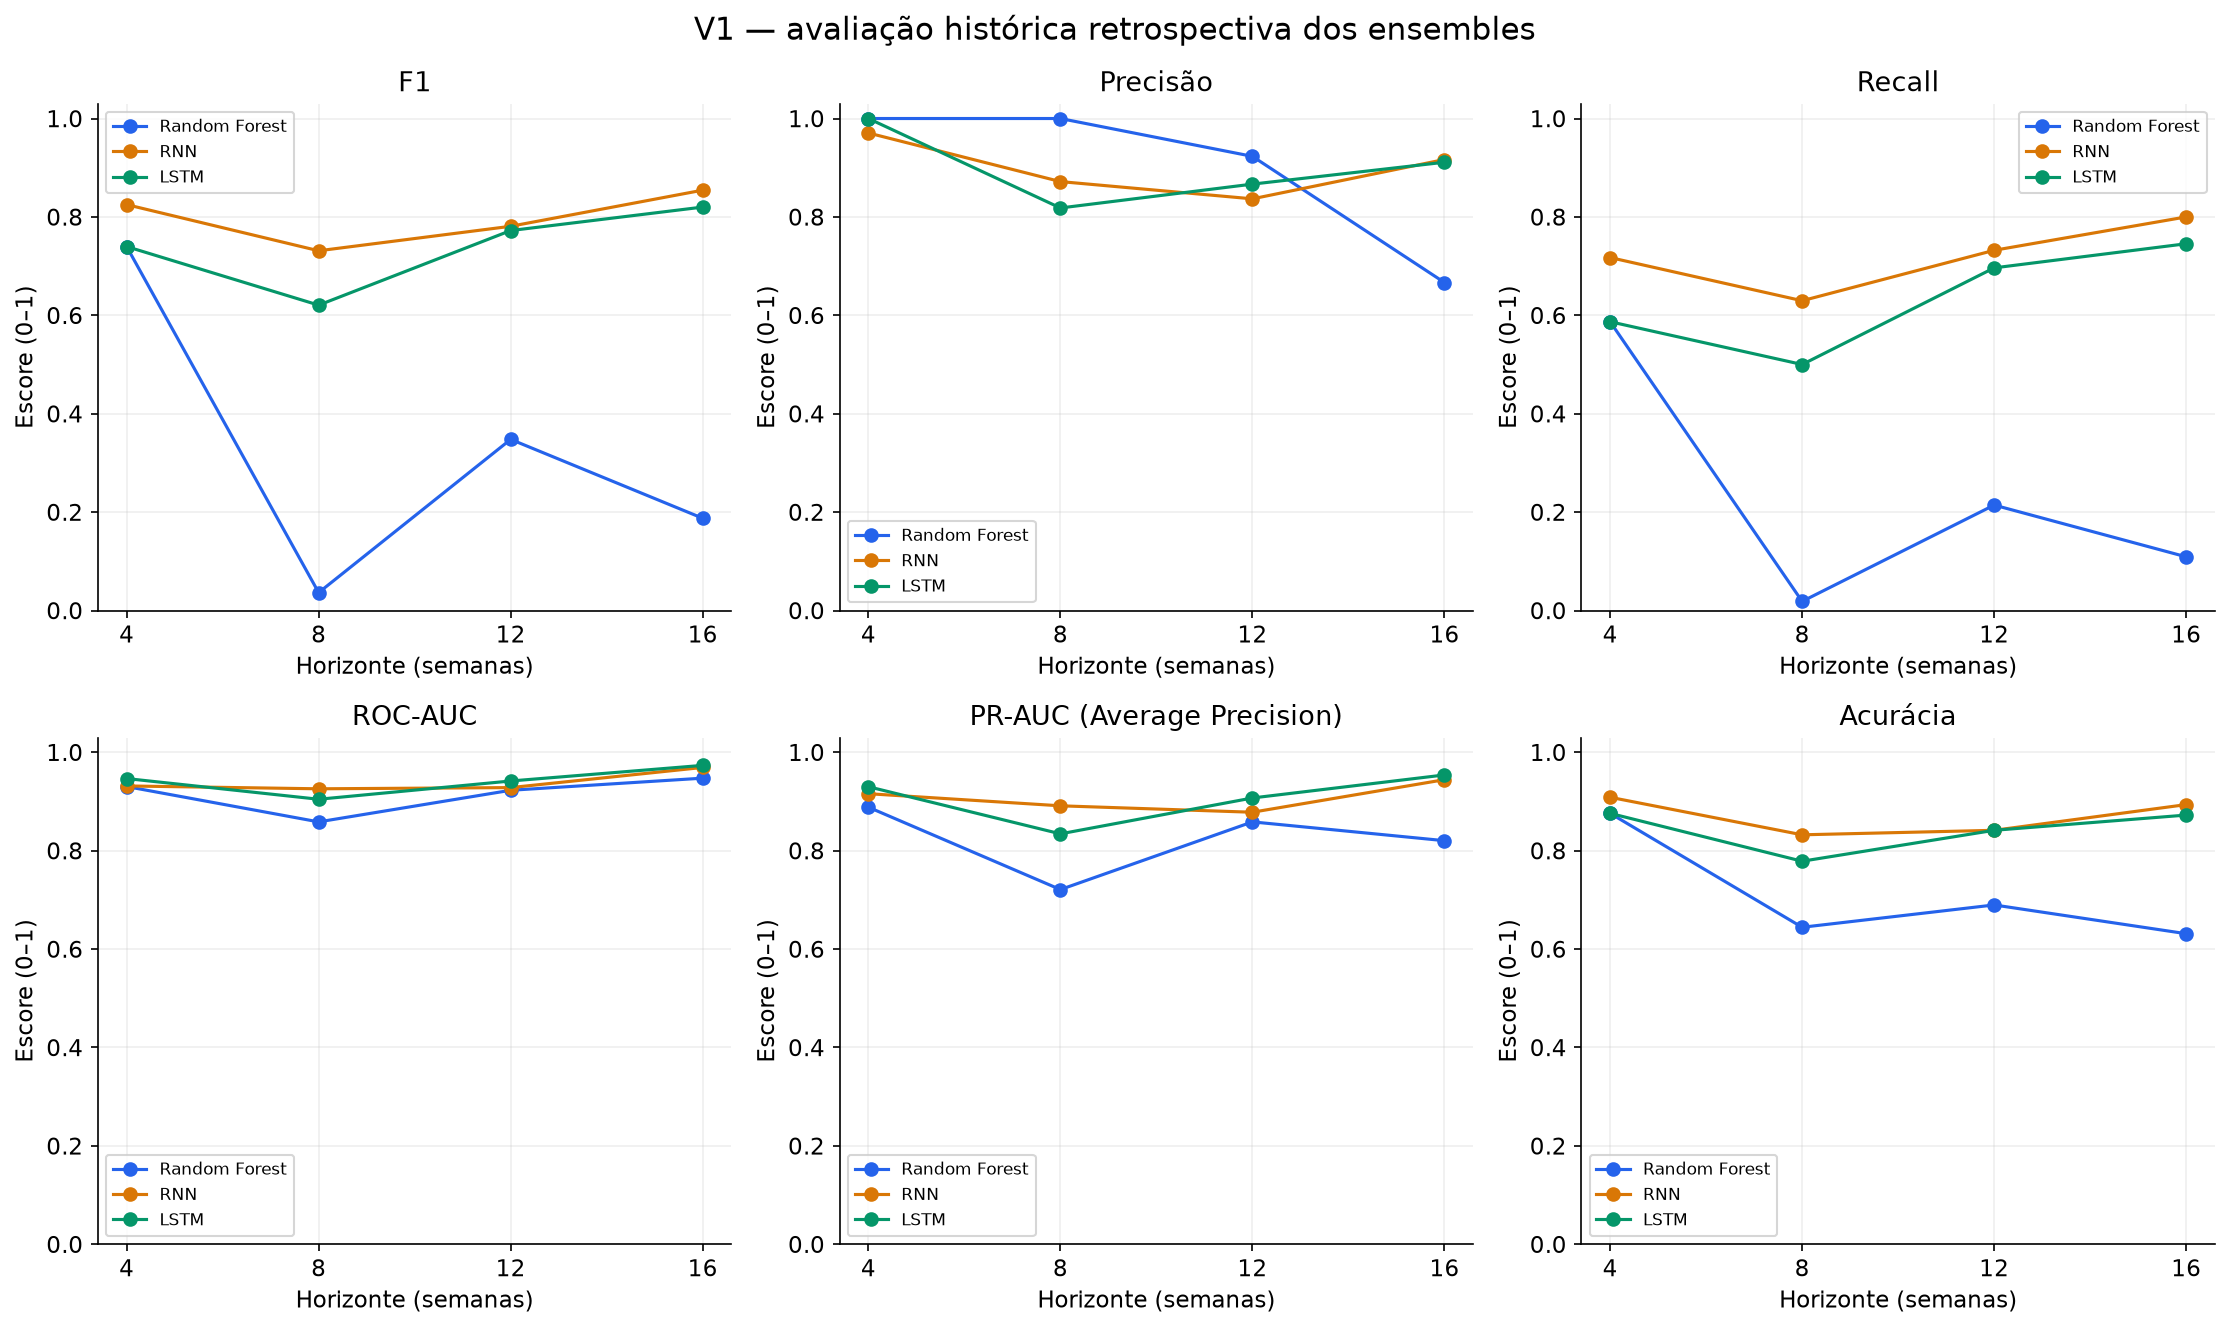

Previsão para a semana de 25/01/2026
Aumento de casos previsto: sim
Critério: Aumento de pelo menos 50% em relação à média das quatro semanas anteriores à emissão da previsão.
Desempenho histórico do modelo: 87,6% de acerto em 153 semanas avaliadas.
Modelo experimental.
As previsões podem errar devido a particularidades locais, mudanças na transmissão, no clima e nos registros de casos. Não devem ser tomadas como verdade absoluta nem como confirmação de surto.
A taxa de acerto descreve o desempenho histórico no conjunto avaliado; não é a probabilidade de esta previsão individual estar correta.

Catálogo: /media/lorenzo/SSD/Projetos/ML-Dengue/v1/results/catalogo.json
Relatório técnico: /media/lorenzo/SSD/Projetos/ML-Dengue/v1/results/relatorio_tecnico.md


In [4]:
import json
results = PROJECT_ROOT / 'v1/results'
display(Image(filename=str(results / 'comparacao/visao_geral.png')))
example = json.loads((results / 'horizontes/04_semanas/random_forest/previsao.json').read_text())
print(example['textoConclusao'])
print()
print('Catálogo:', results / 'catalogo.json')
print('Relatório técnico:', results / 'relatorio_tecnico.md')


## 6. Retrospectiva: previsto versus observado

Exporta, para cada modelo e horizonte, as semanas da **partição de teste** com
emissão, data-alvo, casos observados, referência do critério, aumento previsto e
observado, acerto e escore não calibrado. Identifica falsos alarmes e aumentos não
detectados. Confere os resultados contra as métricas já calculadas.

A avaliação permanece **retrospectiva e exploratória**. Não estima quantidades
futuras de casos e não representa validação prospectiva independente.

A célula aproveita os arquivos existentes, sem treinar novamente. Salva
`retrospectiva.json` em cada pasta de modelo/horizonte e atualiza o catálogo e o
inventário. Também atualiza a pasta `export` com os JSONs para a futura tela do app.

In [5]:
import runpy
import pandas as pd

retrospectiva_api = runpy.run_path(str(PROJECT_ROOT / 'v1/retrospectiva.py'))
resumo_retrospectiva = retrospectiva_api['export_retrospectives'](
    PROJECT_ROOT / 'v1/results'
)
display(pd.DataFrame(resumo_retrospectiva).round(2))

exportador = runpy.run_path(str(PROJECT_ROOT / 'scripts/export_app_json.py'))
quantidade_json = exportador['export_results'](
    PROJECT_ROOT / 'v1/results',
    PROJECT_ROOT / 'export',
    PROJECT_ROOT / 'mobile/src/generated/results.ts',
)
print(f'Retrospectivas geradas e {quantidade_json} JSONs disponíveis em export.')


       modelo  horizonteSemanas  semanasAvaliadas  acuraciaPercentual  verdadeiro_negativo  falso_positivo  falso_negativo  verdadeiro_positivo
random_forest                 4               153               87.58                  107               0              19                   27
          rnn                 4               153               90.85                  106               1              13                   33
         lstm                 4               153               87.58                  107               0              19                   27
random_forest                 8               149               64.43                   95               0              53                    1
          rnn                 8               149               83.22                   90               5              20                   34
         lstm                 8               149               77.85                   89               6              27              

## 7. Comparação consolidada: sem ENSO, ONI contínuo e ENSO binário

Executa o experimento separado de três representações nos quatro horizontes, mantendo o protocolo da v1. Resultados em `comparacao_ENSO/results`, sem substituir os JSONs do app. As previsões da referência são reproduzidas; as variantes são selecionadas somente pela validação. Veja o notebook `comparacao_ENSO/comparacao_ENSO.ipynb` e o relatório para diferenças pareadas, estabilidade entre sementes e intervalos exploratórios.

O ONI histórico recebe atraso de quatro semanas, uma hipótese de disponibilidade. Não há vintages ou datas originais de publicação; não se apresenta esta comparação como avaliação prospectiva independente.

In [ ]:
import runpy

comparison_api = runpy.run_path(str(PROJECT_ROOT / 'comparacao_ENSO/estudo.py'))
comparison_summary = comparison_api['run_study'](PROJECT_ROOT)
display(comparison_summary.query("split == 'teste'").round(4))
